**Homework 4, question 2d**

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
rng = np.random.default_rng(42)

In [57]:
mu = 0.2
sigma = 0.5
I0=5
ws_0 = wc_0 = 1/2
ws_2 =wc_2= (1+0.2)/2
dt = 0.002
n = 10**4
theta = np.linspace(0.5,4,8)

In [43]:
theta

array([0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. ])

In [45]:
# b predictions, lambda = 0
def p_corr_b(theta):
    denom = 1+ np.exp(-mu*theta/(sigma**2))
    return 1/ denom

def mean_b(theta):
    return (theta/mu)*np.tanh(mu*theta/(2*sigma**2))

In [47]:
# c predictions, lambda >0 (0.2)
lam = 0.2
def g(y):
    return np.exp((-lam*y**2-2*mu*y)/(2*sigma**2))
                  

def p_corr_c(theta):
    num = quad(g,-theta,0)[0]
    denom = quad(g,-theta,theta)[0]
    return num/denom

In [63]:
#lambda = 0
emp0_corr = []
emp0_mean = []

for t in theta:
    r1 = np.full(n, I0,dtype = float)
    r2 = np.full(n, I0,dtype = float)

    hit_time = np.full(n,np.nan)
    correct = np.zeros(n,dtype=bool)
    active = np.ones(n,dtype=bool)

    step = 0
    max_steps = int(100/dt)

    while np.any(active) and step<max_steps:
        idx = np.flatnonzero(active)

        x1 = r1[idx].copy()
        x2 = r2[idx].copy()

        noise1 = sigma * np.sqrt(dt) * rng.standard_normal(len(idx))
        noise2 = sigma * np.sqrt(dt) * rng.standard_normal(len(idx))

        # Euler-Maruyama updates
        r1[idx] += dt * (-x1 + ws_0*x1 - wc_0*x2 + I0 + mu/2) + noise1
        r2[idx] += dt * (-x2 + ws_0*x2 - wc_0*x1 + I0 - mu/2) + noise2

        d = r1[idx] - r2[idx]
        crossed = np.abs(d) >= t

        finished = idx[crossed]
        hit_time[finished] = (step + 1) * dt
        correct[finished] = d[crossed] >= t
        active[finished] = False

        step += 1

    valid = np.isfinite(hit_time)

    emp0_corr.append(np.mean(correct[valid]))
    emp0_mean.append(np.mean(hit_time[valid]))
    

emp0_corr = np.array(emp0_corr)
emp0_mean = np.array(emp0_mean)    

In [65]:
# Theoretical predictions
p_b = np.array([p_corr_b(t) for t in theta])
t_b = np.array([mean_b(t) for t in theta])
p_c = np.array([p_corr_c(t) for t in theta])

In [67]:
# Perfect integrator threshold giving the same accuracy as (c)
theta_pi = sigma**2 / mu * np.log(p_c / (1 - p_c))
t_pi = np.array([mean_b(t) for t in theta_pi])

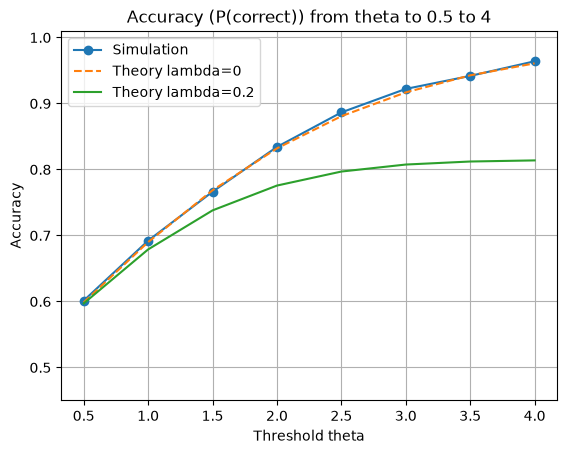

In [87]:
plt.plot(theta, emp0_corr, "o-", label="Simulation")
plt.plot(theta, p_b, "--", label="Theory lambda=0")
plt.plot(theta, p_c, "-", label="Theory lambda=0.2")
plt.xlabel(r"Threshold theta")
plt.ylabel("Accuracy")
plt.ylim(0.45, 1.01)
plt.legend()
plt.grid(True)
plt.title('Accuracy (P(correct)) from theta to 0.5 to 4')
plt.show()

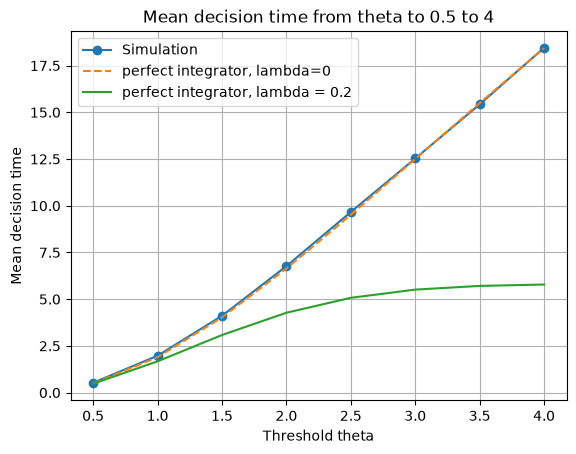

In [93]:
plt.plot(theta, emp0_mean, "o-", label="Simulation")
plt.plot(theta, t_b, "--", label="perfect integrator, lambda=0")
plt.plot(theta, t_pi, "-", label="perfect integrator, lambda = 0.2")
plt.xlabel(r"Threshold theta")
plt.ylabel("Mean decision time")
plt.legend()
plt.grid(True)
plt.title('Mean decision time from theta to 0.5 to 4')
plt.show()

In [97]:
print(" theta | accuracy | perfect integrator, theory lambda>0 | sim time")
for th, a, p, t in zip(theta, emp0_corr, p_c, emp0_mean):
    print(f"{th:5.1f} | {a:12.4f} | {p:15.4f} | {t:8.3f}")

 theta | accuracy | perfect integrator, theory lambda>0 | sim time
  0.5 |       0.6013 |          0.5971 |    0.529
  1.0 |       0.6922 |          0.6789 |    1.975
  1.5 |       0.7663 |          0.7381 |    4.110
  2.0 |       0.8342 |          0.7757 |    6.768
  2.5 |       0.8865 |          0.7969 |    9.665
  3.0 |       0.9221 |          0.8075 |   12.528
  3.5 |       0.9418 |          0.8121 |   15.423
  4.0 |       0.9640 |          0.8138 |   18.457


At theta = 4, the accuracy is almost 1, but the decision time is quite high. With the perfect integrator, it is not as high.